<a href="https://colab.research.google.com/github/victoria1428/HackPrinceton-Fall-2026/blob/main/visionModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Subagent Vision Model

In [49]:
!pip install -q inference-sdk
from google.colab import userdata
from inference_sdk import InferenceHTTPClient

api_key = userdata.get('ROBOFLOW_API_KEY')

client = InferenceHTTPClient(api_url="https://serverless.roboflow.com", api_key=api_key)
MODEL_ID = "victorias-workspace-lw5e8/daily-living-and-fall-detection-1-yolo26n-t1"
FALL_NAME = "falling_emergency_attention"
STAY_SECS = 5
SECS_BETWEEN = 1.0

def label_of(frame): #evaluates one frame
    """frame: an image file path. Returns 1 (fall), 0 (daily life) or None."""
    result = client.infer(frame, model_id=MODEL_ID)
    preds = result["predictions"]
    if not preds:
        return None
    best = max(preds, key=lambda p: p["confidence"])
    return 1 if best["class"] == FALL_NAME else 0

In [50]:
from concurrent.futures import ThreadPoolExecutor
import time

def check_frames_fast(frames, max_workers=20):
    """Runs label_of in parallel across multiple threads to speed up processing."""
    start_time = time.time()

    # make HTTP requests to Roboflow
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        labels = list(executor.map(label_of, frames))

    need = int(STAY_SECS / SECS_BETWEEN)        # frames needed, e.g. 5
    last = labels[-need:]                        # the most recent "need" frames
    falls = sum(1 for l in last if l == 1)
    result = 1 if len(last) == need and falls >= need - 1 else 0

    print(f"Processed {len(frames)} frames in {time.time() - start_time:.2f} seconds.")
    return result

    print("Running parallelized check...")
    print("Alert Status:", check_frames_fast(frames))

In [46]:
import cv2
import matplotlib.pyplot as plt
import random
def check_random_frame(frames):
    # Select an example frame randomly from images
    example_frame = random.choice(frames)

    # Determine the label using the label_of function of the single frame
    label_id = label_of(example_frame)
    if label_id == 1:
        label_str = "Fall Detected"
    elif label_id == 0:
        label_str = "Normal / Daily Living"
    else:
        label_str = "No prediction or uncertain"

    # Read and display the image with its label
    img = cv2.imread(example_frame)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(img_rgb)
    plt.title(f"File: {example_frame.split('/')[-1]}\nPredicted Label: {label_str} ({label_id})")
    plt.axis('off')
    plt.show()

Sample/Test Run

In [51]:
#direct frames to pngs in test_frames file in content
import glob
frames = sorted(glob.glob("/content/test_frames/*.png"))

Visualizing a random frame prediction...


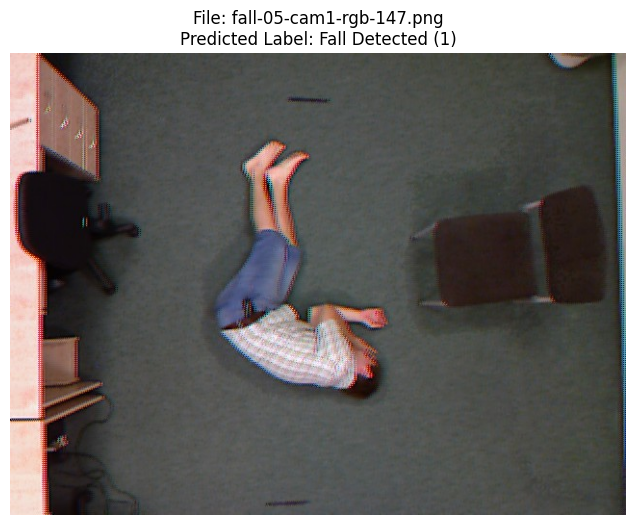

Evaluating total alert status...
Processed 151 frames in 3.30 seconds.
Alert Status (1=Fall Event, 0=Normal): 1


In [54]:
# 1. Call the random frame function
print("Visualizing a random frame prediction...")
check_random_frame(frames)

# 2. Call the multiple frames checking function
print("Evaluating total alert status...")
alert_status = check_frames_fast(frames)
print("Alert Status (1=Fall Event, 0=Normal):", alert_status)